Check time alignment between eeg and et data by looking at blinks and artifacts

In [106]:
import os
import sys
import mne
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append('../..')
from data.data_configs import *

In [107]:
TEST_SUBJECT = "P05"

In [108]:
events_df = pd.read_csv(os.path.join(LABELED_ET_DATA_DIR,f"{TEST_SUBJECT}_labeled_events.csv"),  dtype={'stimulus': str})
fixations_df = events_df[events_df["event_type"] == "Blink"]
fixations_df = fixations_df.sort_values(by='start_time')
fixations_df.head()

,event_type,start_time,end_time,duration_ms,mean_x,mean_y,start_x,start_y,end_x,end_y,fixation_on_airplane,stimulus,eeg_time_start
79,Blink,1842349501,1842557453,207.952,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00070,302168.048
190,Blink,1866275736,1866295744,20.008,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00229,326094.283
192,Blink,1866539710,1866571689,31.979,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00229,326358.257
196,Blink,1867675587,1867747552,71.965,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00229,327494.134
209,Blink,1872475331,1872571366,96.035,NaN,NaN,NaN,NaN,NaN,NaN,NaN,00293,332293.878


In [ ]:
raw_eeg_path = os.path.join(RAW_EEG_DIR, f"{TEST_SUBJECT}.edf")
processed_eeg_path = os.path.join(EEG_DIR, f"{TEST_SUBJECT}.edf")

In [110]:
raw = mne.io.read_raw_edf(raw_eeg_path, preload=True)  # preload=True loads data into memory
processed = mne.io.read_raw_edf(processed_eeg_path, preload=True)  # preload=True loads data into memory
print(raw.get_data().shape)
print(processed.get_data().shape)
assert raw.get_data().shape[1] == processed.get_data().shape[1]

Extracting EDF parameters from ~/Code/Eye_EEG/data/data/raw_data/EEG_clean/P05.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1106499  =      0.000 ...  2212.998 secs...
Extracting EDF parameters from ~/Code/Eye_EEG/data/data/raw_data/EEG_clean/P05.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1106499  =      0.000 ...  2212.998 secs...
(33, 1106500)
(33, 1106500)


In [111]:
processed = mne.io.read_raw_edf(processed_eeg_path, preload=True)  # preload=True loads data into memory

Extracting EDF parameters from ~/Code/Eye_EEG/data/data/raw_data/EEG_clean/P05.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1106499  =      0.000 ...  2212.998 secs...


In [112]:
# High-pass and low-pass
raw.filter(l_freq=0.1, h_freq=80, fir_design='firwin')

# Notch filter at 50 Hz (can also remove 48-52 Hz if needed)
raw.notch_filter(freqs=50, fir_design='firwin')

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.1 - 80 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.10
- Lower transition bandwidth: 0.10 Hz (-6 dB cutoff frequency: 0.05 Hz)
- Upper passband edge: 80.00 Hz
- Upper transition bandwidth: 20.00 Hz (-6 dB cutoff frequency: 90.00 Hz)
- Filter length: 16501 samples (33.002 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband

<RawEDF | P05.edf, 33 x 1106500 (2213.0 s), ~278.6 MiB, data loaded>

In [113]:
import matplotlib.pyplot as plt

# Take the first 5 fixations (in seconds)
fixations_sec = fixations_df.iloc[63:68]["eeg_time_start"].values / 1000  # convert ms -> s
fixations_labels = fixations_df.iloc[63:68]["fixation_on_airplane"].values

# Define start and end for EEG interval
start_sec = fixations_sec[0]
end_sec = fixations_sec[-1]

# Crop the raw EEG to that interval
raw_interval = raw.copy().crop(tmin=start_sec, tmax=end_sec)
data, times = raw_interval.get_data(return_times=True)

In [114]:
data = data[:20]

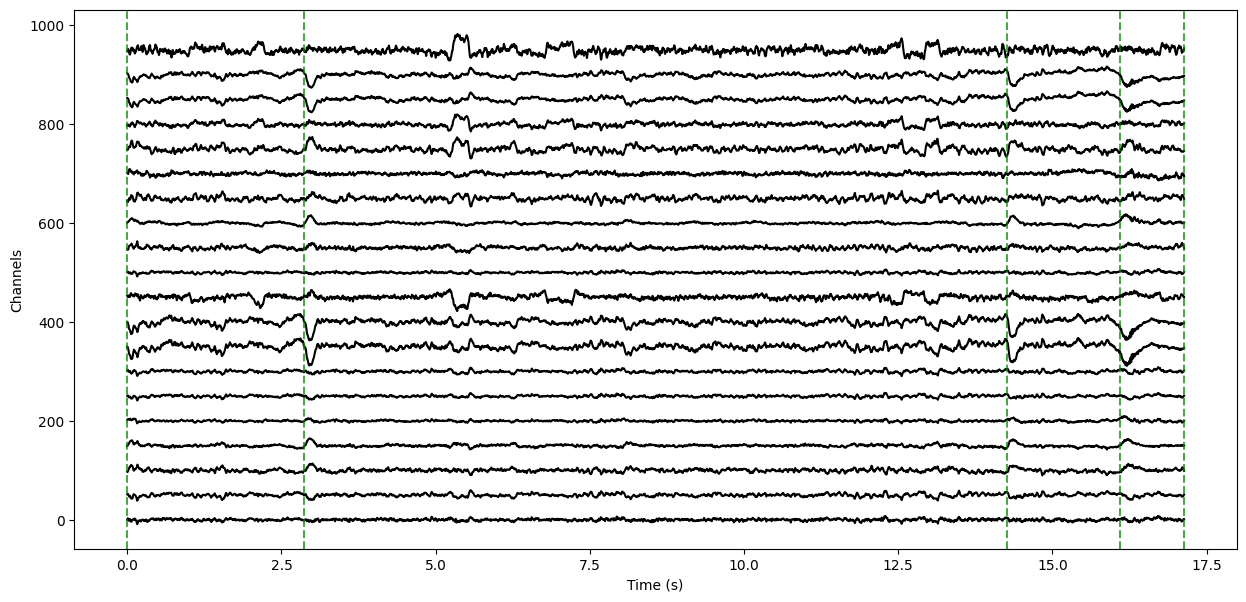

In [115]:
# Make x-axis relative to interval
times = times - times[0]

# Convert to µV
data_uV = data * 1e6
offset = 50

plt.figure(figsize=(15, 7))
for i, ch_data in enumerate(data_uV):
    plt.plot(times, ch_data + i*offset, color='k')

# Plot fixations relative to start of interval
fixations_rel = fixations_sec - fixations_sec[0]

for f in fixations_rel:
    plt.axvline(f, color='g', linestyle='--', alpha=0.7)

plt.xlabel("Time (s)")
plt.ylabel("Channels")
plt.show()
